<a href="https://colab.research.google.com/github/noeliacualina/Procesamiento_digital_imagenes/blob/TrabajoPractico_2/TP2/TP2_Integrador_PDI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**UGR**

# Trabajo Práctico N°2 — Integrador Final
## Procesamiento Digital de Imágenes (V.CLCD2.10.1)

**Integrantes (hasta 4):**
- Martinez Gisela
- Cualina Noelia
- Carabajal Javier
- Carbajar Leonardo
---

### Cómo usar esta plantilla
- Cada sección corresponde a un paso del enunciado. **Completen los `# TODO`** de cada función.
- En cada sección hay una celda **"Decisiones y observaciones"**: ahí va la documentación (parte del Informe).
- El notebook debe **correr de arriba a abajo sin errores** antes de entregar (Entorno → Reiniciar y ejecutar todo).
- Muestren siempre la imagen **antes y después** de cada técnica.
- La entrega final = este notebook ejecutado + (opcional) export a PDF para subir a la plataforma.


**Objetivo**

Extender el sistema de detección y clasificación de formas geométricas del TP1 para que funcione sobre imágenes reales (con ruido, distintas condiciones de iluminación, perspectiva y color), integrando las técnicas vistas en toda la materia, utilizando OpenCV en Google Colab.


**Descripción**
Partiendo del clasificador desarrollado en el TP1, deberán construir un sistema completo que adquiera, mejore, restaure, transforme, segmente y analice imágenes, clasificando las formas por su geometría y por su color. Pueden presentarlo en grupos de hasta 4 alumnos.


**Pasos del proyecto**

Punto de partida (TP1)

•  Reutilizar el clasificador de formas del TP1 como función base y usarlo como línea de comparación.
Adquisición y formatos

•  Armar un conjunto propio de al menos 8 imágenes con formas, en condiciones variadas.
•  Comparar una misma imagen guardada en BMP, PNG y JPEG (tamaño y calidad).

Mejora y restauración

•  Mostrar el efecto de la cuantización de niveles de gris y del submuestreo (aliasing).
•  Mejorar el contraste con ajuste lineal, corrección gamma y ecualización de histograma.
•  Agregar ruido (sal y pimienta y gaussiano) y comparar filtros de media, gaussiano y mediana.

Transformaciones y morfología

•  Aplicar rotación, escalado, traslación y corregir la perspectiva de una figura (homografía).
•  Aplicar erosión, dilatación, apertura y cierre con distintos elementos estructurantes.

Detección de bordes y segmentación

•  Comparar los operadores Sobel, Prewitt y Laplaciano (y Canny).
•  Segmentar las figuras del fondo (umbralización / Otsu) y contar cuántas hay.

Color

•  Separar los canales RGB y convertir a HSV.
•  Segmentar las figuras por color en HSV y aplicar un mapa de pseudocolor.

Sistema integrador

•  Encadenar las técnicas anteriores en un único pipeline que reciba una imagen real y devuelva cada forma detectada con su tipo, su color y el conteo total.
•  Comparar la robustez del sistema final contra el clasificador del TP1.


**Entregables**

1) Código fuente: notebook de Google Colab ejecutable y comentado.
2) Informe técnico: documento (puede ser el mismo notebook con celdas de texto, o un archivo aparte en PDF) donde expliquen TÉCNICAMENTE cómo resolvieron el trabajo, al igual que en el TP1. Para cada etapa deben indicar:
•  Qué técnica/función de OpenCV usaron y para qué.
•  Por qué tomaron esa decisión y qué parámetros eligieron (umbral, gamma, kernels, rangos HSV, filtros, etc.).
•  Qué resultado obtuvieron, mostrando la imagen antes y después.
El informe cierra con una comparación de la robustez del sistema integrador frente al clasificador del TP1 y con las conclusiones (qué aprendieron, limitaciones y posibles mejoras).
3) Defensa oral del trabajo en grupo: todos los integrantes deben poder explicar cualquier parte.


## 0. Configuración e importación de librerías

In [4]:
import cv2
import numpy as np
import math
import os
import matplotlib.pyplot as plt

# Si trabajan en Google Colab, descomenten para subir imágenes:
# from google.colab import files

def mostrar(imagenes, titulos=None, cols=3, cmap=None):
    """Muestra una o varias imágenes en una grilla.

    Args:
        imagenes: imagen única (ndarray) o lista de imágenes.
        titulos:  título o lista de títulos (opcional).
        cols:     columnas de la grilla.
        cmap:     'gray' para imágenes en escala de grises; None para color.
    """
    if not isinstance(imagenes, (list, tuple)):
        imagenes = [imagenes]
    if titulos is None:
        titulos = [""] * len(imagenes)
    elif not isinstance(titulos, (list, tuple)):
        titulos = [titulos]

    n = len(imagenes)
    filas = math.ceil(n / cols)
    plt.figure(figsize=(cols * 4, filas * 4))
    for i, img in enumerate(imagenes):
        plt.subplot(filas, cols, i + 1)
        # Si es color (BGR de OpenCV) lo paso a RGB para matplotlib
        if cmap is None and img.ndim == 3:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(img, cmap=cmap or 'gray')
        plt.title(titulos[i] if i < len(titulos) else "")
        plt.axis('off')
    plt.tight_layout()
    plt.show()


## 1. Punto de partida — Clasificador del TP1

Reutilizar el clasificador de formas del TP1 como **función base** y línea de comparación.


In [ ]:
def clasificar_formas(img_bgr):
    """Clasificador del TP1: detecta y clasifica formas geométricas en una imagen.

    Reutilizar acá la lógica del TP1 (gris -> suavizado -> umbral -> contornos ->
    approxPolyDP por número de vértices + relación de aspecto).

    Args:
        img_bgr: imagen de entrada en BGR.
    Returns:
        (img_resultado, detecciones)
        img_resultado: copia de la imagen con las formas rotuladas.
        detecciones:   lista de dicts, p.ej. {"tipo": "Cuadrado", "contorno": cnt}
    """
    # TODO: pegar y adaptar el clasificador del TP1.
    raise NotImplementedError


In [ ]:
# --- Ejemplo de uso (descomentar y adaptar) ---
# img = cv2.imread("formas_tp1.png")          # imagen ideal del TP1
# resultado, detecciones = clasificar_formas(img)
# print(f"Formas detectadas: {len(detecciones)}")
# mostrar([img, resultado], ["Original", "Clasificado TP1"], cols=2)


## 2. Adquisición y formatos

- Armar un conjunto propio de **al menos 8 imágenes** con formas, en condiciones variadas.
- Comparar una misma imagen guardada en **BMP, PNG y JPEG** (tamaño y calidad).


In [ ]:
def cargar_imagenes(rutas):
    """Carga una lista de imágenes desde disco (BGR)."""
    # TODO: leer cada ruta con cv2.imread y devolver un dict {nombre: img}
    raise NotImplementedError


def comparar_formatos(img_bgr, nombre_base="muestra"):
    """Guarda la misma imagen en BMP, PNG y JPEG y compara tamaño en disco y calidad.

    Pista: cv2.imwrite(f"{nombre_base}.jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 90])
           os.path.getsize(ruta) para el tamaño en bytes.
    """
    # TODO: guardar en .bmp/.png/.jpg, comparar os.path.getsize y mostrar diferencias.
    raise NotImplementedError


In [ ]:
# --- Ejemplo de uso (descomentar y adaptar) ---
# imgs = cargar_imagenes(["img1.jpg", "img2.png", "img3.bmp"])
# mostrar(list(imgs.values()), list(imgs.keys()))
#
# comparar_formatos(imgs["img1.jpg"], nombre_base="muestra")


**Decisiones y observaciones:**
_(¿Qué formato pesa más? ¿Cuál pierde calidad y por qué? Con/sin pérdida.)_


## 3. Mejora y restauración

- Cuantización de niveles de gris y submuestreo (**aliasing**).
- Contraste: ajuste lineal, **corrección gamma** y **ecualización de histograma**.
- Ruido (**sal y pimienta** y **gaussiano**) y comparación de filtros media / gaussiano / mediana.


In [ ]:
def cuantizar(img_gray, niveles):
    """Reduce la imagen a 'niveles' de gris.

    Pista: paso = 256 // niveles; (img // paso) * paso
    """
    # TODO
    raise NotImplementedError


def submuestrear(img, factor):
    """Reduce y vuelve a ampliar para evidenciar aliasing.

    Pista: cv2.resize hacia abajo y luego hacia arriba con INTER_NEAREST.
    """
    # TODO
    raise NotImplementedError


def ajuste_lineal(img, alpha=1.5, beta=0):
    """Contraste/brillo lineal. Pista: cv2.convertScaleAbs(img, alpha=alpha, beta=beta)."""
    # TODO
    raise NotImplementedError


def correccion_gamma(img, gamma=1.0):
    """Corrección gamma usando una LUT.

    Pista: tabla = ((np.arange(256)/255.0) ** gamma) * 255 -> cv2.LUT(img, tabla.astype('uint8'))
    """
    # TODO
    raise NotImplementedError


def ecualizar(img_gray):
    """Ecualización de histograma. Pista: cv2.equalizeHist (o CLAHE)."""
    # TODO
    raise NotImplementedError


In [ ]:
# --- Ejemplo de uso (descomentar y adaptar) ---
# gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
# mostrar(
#     [gris, cuantizar(gris, 4), submuestrear(gris, 0.25)],
#     ["Gris", "4 niveles", "Submuestreo (aliasing)"]
# )
# mostrar(
#     [gris, ajuste_lineal(gris, 1.5, 10), correccion_gamma(gris, 0.5), ecualizar(gris)],
#     ["Gris", "Lineal", "Gamma 0.5", "Ecualizada"], cols=4
# )


In [ ]:
def ruido_sal_pimienta(img, prob=0.02):
    """Agrega ruido sal y pimienta. Pista: máscara aleatoria -> píxeles a 0 y a 255."""
    # TODO
    raise NotImplementedError


def ruido_gaussiano(img, sigma=20):
    """Agrega ruido gaussiano. Pista: np.random.normal(0, sigma, img.shape) y sumar (clip 0-255)."""
    # TODO
    raise NotImplementedError


def comparar_filtros(img_ruidosa):
    """Aplica filtro de media, gaussiano y mediana y los muestra para comparar.

    Pista: cv2.blur, cv2.GaussianBlur, cv2.medianBlur.
    """
    # TODO
    raise NotImplementedError


In [ ]:
# --- Ejemplo de uso (descomentar y adaptar) ---
# ruidosa = ruido_sal_pimienta(gris, 0.02)
# comparar_filtros(ruidosa)
#
# ruidosa_g = ruido_gaussiano(gris, 20)
# comparar_filtros(ruidosa_g)


**Decisiones y observaciones:**
_(¿Qué filtro funciona mejor con cada tipo de ruido? ¿Qué gamma elegiste y por qué?)_



## 4. Transformaciones geométricas y morfología

- Rotación, escalado, traslación y **corrección de perspectiva (homografía)**.
- Erosión, dilatación, apertura y cierre con distintos **elementos estructurantes**.



In [ ]:
def rotar(img, angulo, escala=1.0):
    """Rota la imagen. Pista: cv2.getRotationMatrix2D(centro, angulo, escala) + cv2.warpAffine."""
    # TODO
    raise NotImplementedError


def escalar(img, fx, fy):
    """Escala la imagen. Pista: cv2.resize(img, None, fx=fx, fy=fy)."""
    # TODO
    raise NotImplementedError


def trasladar(img, tx, ty):
    """Traslada la imagen. Pista: M = np.float32([[1,0,tx],[0,1,ty]]) + cv2.warpAffine."""
    # TODO
    raise NotImplementedError


def corregir_perspectiva(img, pts_origen, pts_destino):
    """Endereza una figura fotografiada en ángulo.

    Pista: M = cv2.getPerspectiveTransform(pts_origen, pts_destino) + cv2.warpPerspective.
    """
    # TODO
    raise NotImplementedError


def operaciones_morfologicas(img_bin, tam_kernel=5):
    """Erosión, dilatación, apertura y cierre. Devuelve un dict para comparar.

    Pista: kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (tam, tam));
           cv2.erode / cv2.dilate / cv2.morphologyEx(..., MORPH_OPEN / MORPH_CLOSE).
    """
    # TODO
    raise NotImplementedError


In [ ]:
# --- Ejemplo de uso (descomentar y adaptar) ---
# mostrar(
#     [img, rotar(img, 30), escalar(img, 0.5, 0.5), trasladar(img, 40, 20)],
#     ["Original", "Rotada 30\u00b0", "Escalada 0.5", "Trasladada"], cols=4
# )
#
# # Los puntos para la homografia deben ser np.float32:
# pts_o = np.float32([[0, 0], [300, 0], [0, 300], [300, 300]])
# pts_d = np.float32([[20, 30], [280, 10], [10, 290], [290, 300]])
# mostrar(corregir_perspectiva(img, pts_o, pts_d), "Perspectiva corregida")
#
# morf = operaciones_morfologicas(mascara_bin, 5)
# mostrar(list(morf.values()), list(morf.keys()), cols=4, cmap="gray")


**Decisiones y observaciones:**
_(¿Qué elemento estructurante usaste? ¿Para qué sirvió la apertura vs el cierre en tus imágenes?)_


## 5. Detección de bordes y segmentación

- Comparar **Sobel, Prewitt y Laplaciano** (y **Canny**).
- Segmentar las figuras del fondo (**umbralización / Otsu**) y **contar cuántas hay**.


In [ ]:
def detectar_bordes(img_gray):
    """Aplica Sobel, Prewitt, Laplaciano y Canny. Devuelve un dict {nombre: imagen}.

    Pista Prewitt: kernels manuales con cv2.filter2D
        kx = np.array([[-1,0,1],[-1,0,1],[-1,0,1]]); ky = kx.T
    """
    # TODO
    raise NotImplementedError


def segmentar_otsu(img_gray):
    """Binariza con Otsu. Pista: cv2.threshold(img, 0, 255, THRESH_BINARY_INV + THRESH_OTSU)."""
    # TODO
    raise NotImplementedError


def contar_figuras(img_bin):
    """Cuenta las figuras presentes.

    Pista: cv2.findContours (filtrar por área) y len(); o cv2.connectedComponents.
    """
    # TODO
    raise NotImplementedError


In [ ]:
# --- Ejemplo de uso (descomentar y adaptar) ---
# bordes = detectar_bordes(gris)
# mostrar(list(bordes.values()), list(bordes.keys()), cols=4, cmap="gray")
#
# binaria = segmentar_otsu(gris)
# print(f"Figuras detectadas: {contar_figuras(binaria)}")
# mostrar(binaria, "Otsu", cmap="gray")


**Decisiones y observaciones:**
_(¿Qué operador de bordes dio mejor resultado? ¿Cuántas figuras detectó Otsu vs las reales?)_


## 6. Color

- Separar los canales **RGB** y convertir a **HSV**.
- Segmentar las figuras **por color** en HSV y aplicar un **mapa de pseudocolor**.


In [ ]:
def separar_canales(img_bgr):
    """Separa los canales B, G, R. Pista: cv2.split."""
    # TODO
    raise NotImplementedError


def a_hsv(img_bgr):
    """Convierte a HSV. Pista: cv2.cvtColor(img, cv2.COLOR_BGR2HSV)."""
    # TODO
    raise NotImplementedError


def segmentar_por_color(img_bgr, rango_bajo, rango_alto):
    """Devuelve una máscara con los píxeles dentro del rango HSV indicado.

    Pista: hsv = cvtColor(...); mascara = cv2.inRange(hsv, rango_bajo, rango_alto).
    """
    # TODO
    raise NotImplementedError


def color_dominante(img_bgr, mascara=None):
    """Devuelve el nombre del color predominante (rojo/verde/azul/amarillo/...).

    Pista: promedio de H en HSV dentro de la máscara y mapear a un nombre.
    """
    # TODO
    raise NotImplementedError


def pseudocolor(img_gray, colormap=cv2.COLORMAP_JET):
    """Aplica un mapa de pseudocolor. Pista: cv2.applyColorMap(img, colormap)."""
    # TODO
    raise NotImplementedError


In [ ]:
# --- Ejemplo de uso (descomentar y adaptar) ---
# b, g, r = separar_canales(img)
# mostrar([b, g, r], ["Azul", "Verde", "Rojo"], cmap="gray")
#
# # Rango HSV aproximado para verde (ajustar a tus imagenes):
# mascara = segmentar_por_color(img, np.array([40, 50, 50]), np.array([80, 255, 255]))
# mostrar(mascara, "Mascara por color", cmap="gray")
#
# print("Color dominante:", color_dominante(img))
# mostrar(pseudocolor(gris), "Pseudocolor")


**Decisiones y observaciones:**
_(¿Por qué HSV es mejor que RGB para segmentar por color? ¿Qué rangos elegiste?)_


## 7. Sistema integrador

- Encadenar todo en un **único pipeline** que reciba una imagen real y devuelva, por cada
  forma detectada, su **tipo** y su **color**, más el **conteo total**.
- Comparar la **robustez** del sistema final contra el clasificador del TP1.


In [ ]:
def pipeline_integrador(img_bgr):
    """Pipeline completo sobre una imagen real.

    Pasos sugeridos:
        1) Pre-procesar (gris -> reducir ruido -> Otsu).
        2) Morfología para limpiar la máscara.
        3) findContours y, por cada forma:
              - tipo  = clasificación por vértices (approxPolyDP)
              - color = color_dominante() dentro de la máscara de esa forma
        4) Dibujar tipo + color sobre la imagen y contar el total.

    Returns:
        (img_anotada, detecciones, total)
        detecciones: lista de dicts {"tipo": ..., "color": ..., "centro": (x,y)}
    """
    # TODO
    raise NotImplementedError


def comparar_robustez(img_real):
    """Corre el clasificador crudo del TP1 y el pipeline integrador sobre la MISMA imagen
    real y muestra ambos resultados lado a lado para evidenciar la mejora."""
    # TODO: clasificar_formas(img_real)  vs  pipeline_integrador(img_real)
    raise NotImplementedError


In [ ]:
# --- Ejemplo de uso (descomentar y adaptar) ---
# real = cv2.imread("foto_real.jpg")
# anotada, detecciones, total = pipeline_integrador(real)
# print(f"Total de formas: {total}")
# for d in detecciones:
#     print(d["tipo"], d["color"], d["centro"])
# mostrar(anotada, "Pipeline integrador")
#
# comparar_robustez(real)


## 8. Informe y conclusiones

Completar (esto es parte de la nota — entregable "Informe"):

**a) Metodología.** Breve descripción del flujo de trabajo y herramientas usadas.

**b) Decisiones tomadas.** Parámetros y técnicas elegidas y por qué (umbral, gamma, kernels,
rangos HSV, filtros, etc.).

**c) Resultados.** Imágenes antes/después de las etapas clave y qué se observa.

**d) Comparación de robustez.** ¿En qué falla el clasificador del TP1 sobre imágenes reales
y cómo lo resuelve el pipeline integrador? (apoyarse en `comparar_robustez`).

**e) Conclusiones.** Qué aprendieron, limitaciones del sistema y posibles mejoras.

---
_Recordatorio: antes de entregar, ejecutar todo de cero (Entorno → Reiniciar y ejecutar todo)
y verificar que no haya errores ni celdas calculadas que no se usen._


# Trabajo Práctico N°2 — Integrador Final


## Carga de Imagenes

In [1]:
!unzip -o imagenes_TP2.zip
!ls imagenes

Archive:  imagenes_TP2.zip
   creating: imagenes/
  inflating: imagenes/06_naranja.jpg  
  inflating: imagenes/04_cubo_arriba.jpg  
  inflating: imagenes/03_granito_5objetos.jpg  
  inflating: imagenes/08_cubo_sombra.jpg  
  inflating: imagenes/07_pelota_servilleta.jpg  
  inflating: imagenes/10_poca_luz.jpg  
  inflating: imagenes/09_cubo_inclinado.jpg  
  inflating: imagenes/05_pelota_blanca.jpg  
  inflating: imagenes/01_cesped_6objetos.jpg  
  inflating: imagenes/02_cesped_5objetos.jpg  
01_cesped_6objetos.jpg	 05_pelota_blanca.jpg	   09_cubo_inclinado.jpg
02_cesped_5objetos.jpg	 06_naranja.jpg		   10_poca_luz.jpg
03_granito_5objetos.jpg  07_pelota_servilleta.jpg
04_cubo_arriba.jpg	 08_cubo_sombra.jpg


## 0. Configuración e importación de librerías

In [14]:
import cv2
import numpy as np
import math
import os
import matplotlib.pyplot as plt


def mostrar(imagenes, titulos=None, cols=3, cmap=None):
    """Muestra una o varias imágenes en una grilla.

    Args:
        imagenes: imagen única (ndarray) o lista de imágenes.
        titulos:  título o lista de títulos (opcional).
        cols:     columnas de la grilla.
        cmap:     'gray' para imágenes en escala de grises; None para color.
    """
    if not isinstance(imagenes, (list, tuple)):
        imagenes = [imagenes]
    if titulos is None:
        titulos = [""] * len(imagenes)
    elif not isinstance(titulos, (list, tuple)):
        titulos = [titulos]

    n = len(imagenes)
    filas = math.ceil(n / cols)
    plt.figure(figsize=(cols * 4, filas * 4))
    for i, img in enumerate(imagenes):
        plt.subplot(filas, cols, i + 1)
        # Si es color (BGR de OpenCV) lo paso a RGB para matplotlib
        if cmap is None and img.ndim == 3:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            #plt.imshow(img, cmap=cmap or 'gray')
            plt.imshow(img, cmap=cmap or 'gray', vmin=0, vmax=255)
        plt.title(titulos[i] if i < len(titulos) else "")
        plt.axis('off')
    plt.tight_layout()
    plt.show()


### 1. Clasificador del TP1

In [15]:
import subprocess
import nbformat

# Trae el clasificador del TP1 desde GitHub ----
REPO_TP1 = "https://github.com/noeliacualina/Procesamiento_digital_imagenes.git"
CARPETA_TP1 = "Procesamiento_digital_imagenes"

if not os.path.isdir(CARPETA_TP1):
    subprocess.run(["git", "clone", "-q", "-b", "TrabajoPractico_1",
                    REPO_TP1, CARPETA_TP1], check=True)

nb_tp1 = nbformat.read(f"{CARPETA_TP1}/TrabajoPractico_N1.ipynb", as_version=4)
for celda in nb_tp1.cells:
    if celda.cell_type == "code" and "def clasificar_forma(" in celda.source:
        espacio = {"cv2": cv2, "np": np}
        exec(celda.source, espacio)
        clasificar_forma_tp1 = espacio["clasificar_forma"]


# Funcion Clasificar
def clasificar_formas(img_bgr):
    """Clasificador del TP1: detecta y clasifica formas geométricas en una imagen.

    Reutilizar acá la lógica del TP1 (gris -> suavizado -> umbral -> contornos ->
    approxPolyDP por número de vértices + relación de aspecto).

    Args:
        img_bgr: imagen de entrada en BGR.
    Returns:
        (img_resultado, detecciones)
        img_resultado: copia de la imagen con las formas rotuladas.
        detecciones:   lista de dicts, p.ej. {"tipo": "Cuadrado", "contorno": cnt}

    """
    gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    suave = cv2.GaussianBlur(gris, (5, 5), 0)
    bordes = cv2.Canny(suave, 50, 150)
    contornos, _ = cv2.findContours(bordes, cv2.RETR_EXTERNAL,
                                    cv2.CHAIN_APPROX_SIMPLE)

    alto, ancho = gris.shape
    area_minima = alto * ancho * 0.0001
    escala = max(0.6, min(alto, ancho) / 600)
    resultado = img_bgr.copy()
    detecciones = []

    for contorno in contornos:
        if cv2.contourArea(contorno) <= area_minima:
            continue
        perimetro = cv2.arcLength(contorno, True)
        aproximacion = cv2.approxPolyDP(contorno, 0.02 * perimetro, True)
        tipo = clasificar_forma_tp1(contorno, aproximacion)
        detecciones.append({"tipo": tipo, "contorno": contorno})
        if tipo == "No identificada":
            continue
        cv2.drawContours(resultado, [aproximacion], -1, (0, 255, 0), max(2, int(escala * 3)))
        m = cv2.moments(aproximacion)
        if m["m00"] != 0:
            cx, cy = int(m["m10"] / m["m00"]), int(m["m01"] / m["m00"])
            cv2.putText(resultado, tipo, (cx - 40, cy), cv2.FONT_HERSHEY_SIMPLEX,
                        escala, (0, 0, 255), max(2, int(escala * 2)))

    return resultado, detecciones

Contornos analizados: 15
['No identificada', 'Rectangulo', 'No identificada', 'Rectangulo', 'No identificada', 'No identificada', 'No identificada', 'No identificada', 'No identificada', 'No identificada', 'No identificada', 'No identificada', 'Circulo', 'No identificada', 'No identificada']


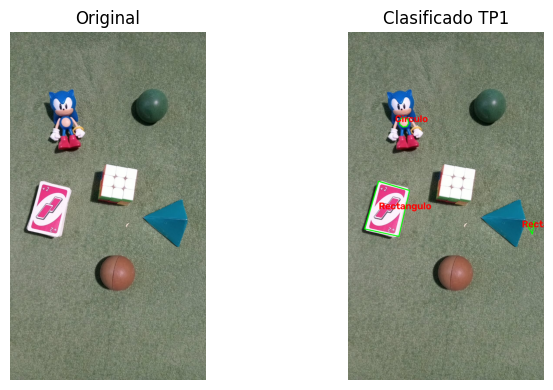

In [16]:
# --- Ejemplo de uso (descomentar y adaptar) ---
img = cv2.imread("imagenes/01_cesped_6objetos.jpg")
resultado, detecciones = clasificar_formas(img)
print(f"Contornos analizados: {len(detecciones)}")
print([d["tipo"] for d in detecciones])
mostrar([img, resultado], ["Original", "Clasificado TP1"], cols=2)

## 2. Adquisición y formatos

In [17]:
def cargar_imagenes(rutas):
    """Carga una lista de imágenes desde disco (BGR)."""
    imagenes = {}
    for ruta in rutas:
        img = cv2.imread(ruta)
        if img is None:
            print(f"No se pudo leer: {ruta}")
            continue
        imagenes[os.path.basename(ruta)] = img
    return imagenes


def comparar_formatos(img_bgr, nombre_base="muestra"):
    """Guarda la misma imagen en BMP, PNG y JPEG y compara tamaño en disco y calidad.

    Pista: cv2.imwrite(f"{nombre_base}.jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 90])
           os.path.getsize(ruta) para el tamaño en bytes.
    """
    rutas = {"BMP": f"{nombre_base}.bmp",
             "PNG": f"{nombre_base}.png",
             "JPEG": f"{nombre_base}.jpg"}

    cv2.imwrite(rutas["BMP"], img_bgr)
    cv2.imwrite(rutas["PNG"], img_bgr)
    cv2.imwrite(rutas["JPEG"], img_bgr, [cv2.IMWRITE_JPEG_QUALITY, 90])

    tam_bmp = os.path.getsize(rutas["BMP"])
    tabla = {}
    print(f"{'Formato':<8}{'Tamaño (KB)':>14}{'% del BMP':>12}{'PSNR (dB)':>16}")
    for formato, ruta in rutas.items():
        tam = os.path.getsize(ruta)
        leida = cv2.imread(ruta)
        if np.array_equal(leida, img_bgr):
            calidad = "sin pérdida"
        else:
            calidad = f"{cv2.PSNR(img_bgr, leida):.2f}"
        tabla[formato] = {"kb": tam / 1024, "porcentaje": 100 * tam / tam_bmp, "psnr": calidad}
        print(f"{formato:<8}{tam / 1024:>14.2f}{100 * tam / tam_bmp:>12.2f}{calidad:>16}")
    return tabla

Imágenes cargadas: 10


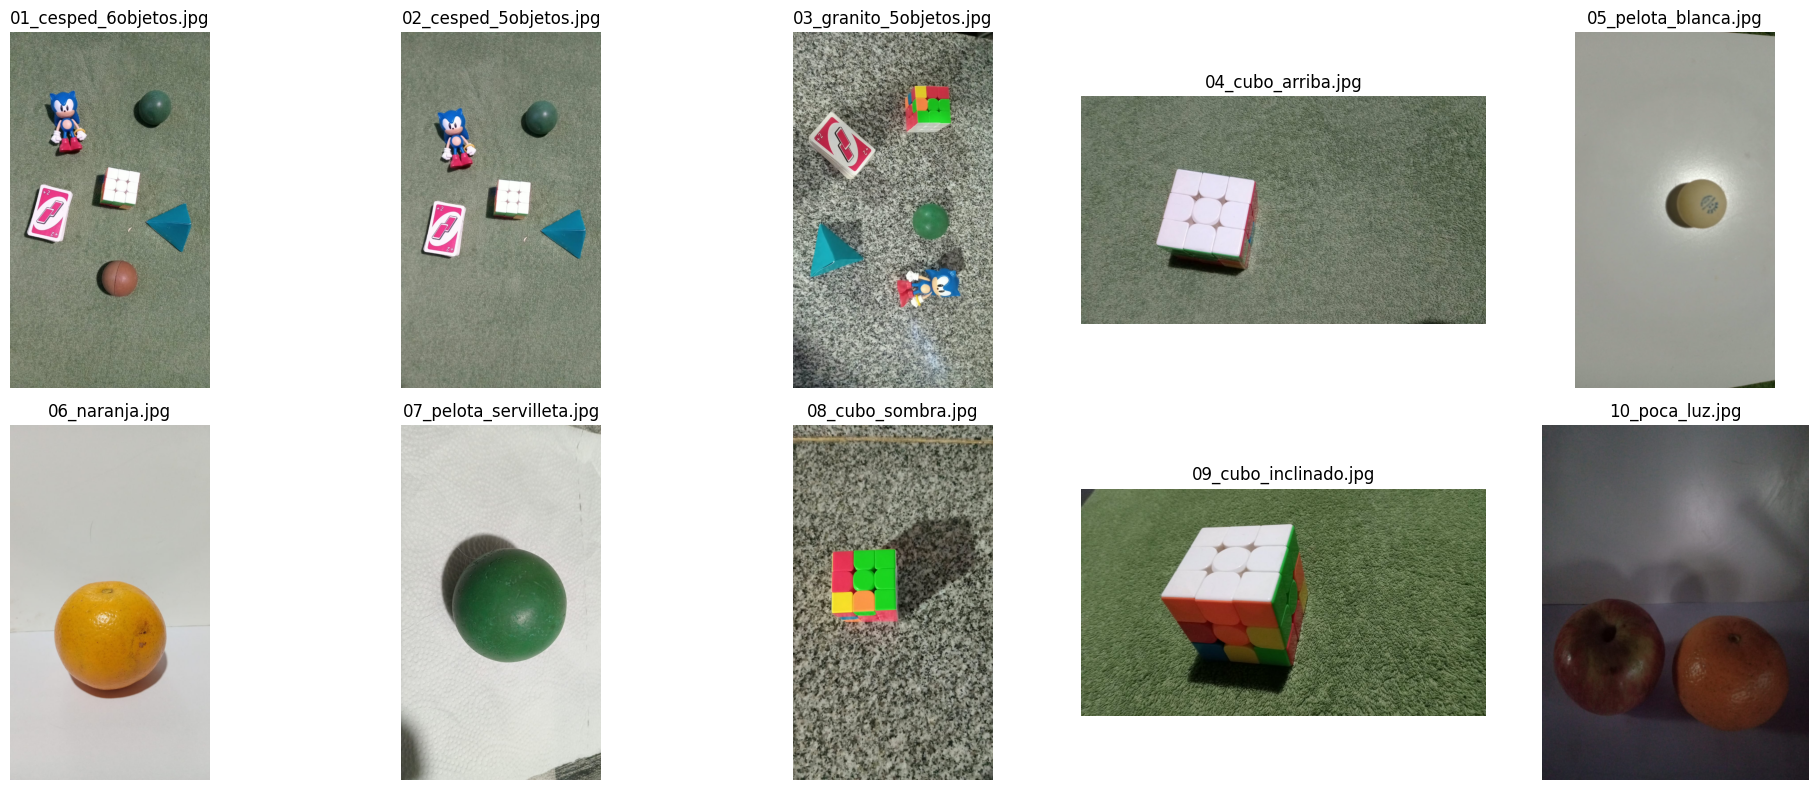

Formato    Tamaño (KB)   % del BMP       PSNR (dB)
BMP            4218.80      100.00     sin pérdida
PNG            3162.07       74.95     sin pérdida
JPEG            490.89       11.64           44.73


In [18]:
rutas = sorted(["imagenes/" + f for f in os.listdir("imagenes")
                if f.lower().endswith((".jpg", ".jpeg", ".png"))])
imgs = cargar_imagenes(rutas)
print(f"Imágenes cargadas: {len(imgs)}")
mostrar(list(imgs.values()), list(imgs.keys()), cols=5)

tabla = comparar_formatos(imgs["01_cesped_6objetos.jpg"], nombre_base="muestra")

**Decisiones y observaciones:**

Se comparó la misma imagen (`01_cesped_6objetos.jpg`, 1600 × 900 px) guardada en BMP, PNG y JPEG con `cv2.imwrite`. El JPEG se guardó con `cv2.IMWRITE_JPEG_QUALITY = 90`. El tamaño en disco se midió con `os.path.getsize` y la calidad con `cv2.PSNR`.

| Formato | Tamaño (KB) | % del BMP | Calidad |
|---|---|---|---|
| BMP | 4218,80 | 100,00 | sin pérdida |
| PNG | 3162,07 | 74,95 | sin pérdida |
| JPEG (calidad 90) | 490,89 | 11,64 | PSNR 44,73 dB |

1. **Qué pesa más:** el BMP, porque guarda cada píxel sin comprimir: 1600 × 900 × 3 bytes = 4.320.000 bytes, unos 4218,75 KB.
2. **PNG:** comprime sin perder datos (al leerlo es idéntico al original), pero en esta foto solo ahorra 25,05 %, porque la textura del césped se comprime poco.
3. **JPEG:** es el más liviano (8,59 veces menos que el BMP), pero **pierde información**. Con calidad 90 la diferencia es chica: 44,73 dB, y por encima de 40 dB casi no se nota a simple vista.
4. **Por qué pierde calidad:** JPEG descarta detalles finos que el ojo percibe poco (transformada y cuantización de coeficientes). Eso lo achica, pero no se puede recuperar el original.
5. **Decisión:** se trabaja con imágenes sin pérdida (PNG). JPEG se usa solo para guardar o enviar, porque si se re-guarda varias veces la calidad sigue bajando.

*Nota: la comparación se hizo con una sola imagen; con una imagen lisa  PNG se comprimiría mucho más.*

## 3. Mejora y restauracion

In [19]:
def cuantizar(img_gray, niveles):
    """Reduce la imagen a 'niveles' de gris.

    Pista: paso = 256 // niveles; (img // paso) * paso
    """
    paso = 256 // niveles
    return ((img_gray // paso) * paso).astype(np.uint8)


def submuestrear(img, factor):
    """Reduce y vuelve a ampliar para evidenciar aliasing.

    Pista: cv2.resize hacia abajo y luego hacia arriba con INTER_NEAREST.
    """
    alto, ancho = img.shape[:2]
    chica = cv2.resize(img, (int(ancho * factor), int(alto * factor)),
    interpolation=cv2.INTER_NEAREST)
    return cv2.resize(chica, (ancho, alto), interpolation=cv2.INTER_NEAREST)



def ajuste_lineal(img, alpha=1.5, beta=0):
    """Contraste/brillo lineal. Pista: cv2.convertScaleAbs(img, alpha=alpha, beta=beta)."""
    return cv2.convertScaleAbs(img, alpha=alpha, beta=beta)


def correccion_gamma(img, gamma=1.0):
    """Corrección gamma usando una LUT.

    Pista: tabla = ((np.arange(256)/255.0) ** gamma) * 255 -> cv2.LUT(img, tabla.astype('uint8'))
    """
    tabla = ((np.arange(256) / 255.0) ** gamma) * 255
    return cv2.LUT(img, tabla.astype("uint8"))


def ecualizar(img_gray):
    """Ecualización de histograma. Pista: cv2.equalizeHist (o CLAHE)."""
    return cv2.equalizeHist(img_gray)


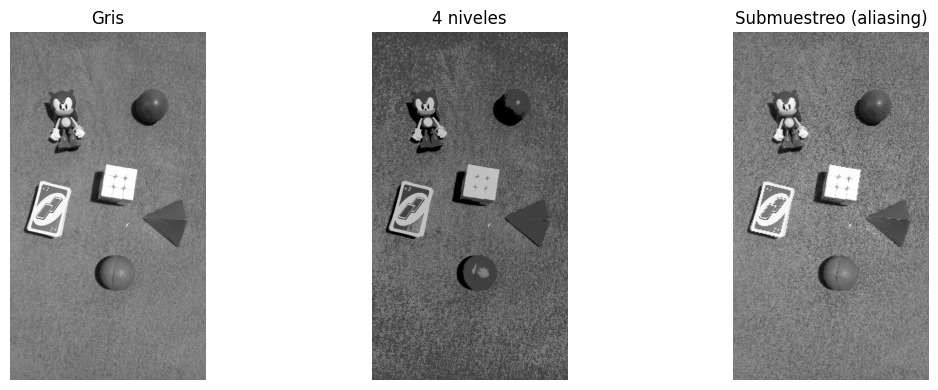

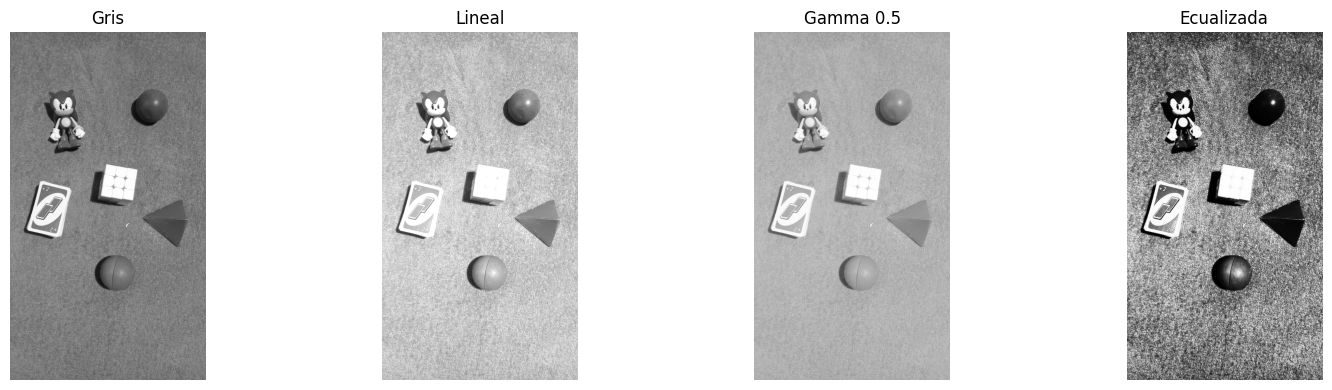

In [20]:
img = imgs["01_cesped_6objetos.jpg"]
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

mostrar([gris, cuantizar(gris, 4), submuestrear(gris, 0.25)],
        ["Gris", "4 niveles", "Submuestreo (aliasing)"])
mostrar([gris, ajuste_lineal(gris, 1.5, 10), correccion_gamma(gris, 0.5), ecualizar(gris)],
        ["Gris", "Lineal", "Gamma 0.5", "Ecualizada"], cols=4)

In [21]:
for nombre, im in [("Original", gris), ("4 niveles", cuantizar(gris, 4)),
                   ("Lineal", ajuste_lineal(gris, 1.5, 10)),
                   ("Gamma 0.5", correccion_gamma(gris, 0.5)),
                   ("Gamma 2.0", correccion_gamma(gris, 2.0)),
                   ("Ecualizada", ecualizar(gris))]:
    print(f"{nombre:<12} media = {im.mean():.2f}   niveles distintos = {len(np.unique(im))}")

Original     media = 124.81   niveles distintos = 253
4 niveles    media = 92.25   niveles distintos = 4
Lineal       media = 192.92   niveles distintos = 162
Gamma 0.5    media = 176.32   niveles distintos = 190
Gamma 2.0    media = 64.71   niveles distintos = 192
Ecualizada   media = 129.23   niveles distintos = 102


**Ruido y filtros**

In [24]:
def ruido_sal_pimienta(img, prob=0.02):
    """Agrega ruido sal y pimienta. Pista: máscara aleatoria -> píxeles a 0 y a 255."""
    ruidosa = img.copy()
    azar = np.random.default_rng(7).random(img.shape[:2])
    ruidosa[azar < prob / 2] = 0            # pimienta (negro)
    ruidosa[azar > 1 - prob / 2] = 255      # sal (blanco)
    return ruidosa


def ruido_gaussiano(img, sigma=20):
    """Agrega ruido gaussiano. Pista: np.random.normal(0, sigma, img.shape) y sumar (clip 0-255)."""
    ruido = np.random.default_rng(7).normal(0, sigma, img.shape)
    return np.clip(img.astype(np.float32) + ruido, 0, 255).astype(np.uint8)


def comparar_filtros(img_ruidosa, img_original=None, ventana=3):
    """Aplica filtro de media, gaussiano y mediana y los muestra para comparar."""
    filtradas = {
        "Media": cv2.blur(img_ruidosa, (ventana, ventana)),
        "Gaussiano": cv2.GaussianBlur(img_ruidosa, (ventana, ventana), 0),
        "Mediana": cv2.medianBlur(img_ruidosa, ventana),
    }
    if img_original is not None:
        print(f"PSNR con ruido: {cv2.PSNR(img_original, img_ruidosa):.2f} dB")
        for nombre, f in filtradas.items():
            print(f"PSNR {nombre:<10}: {cv2.PSNR(img_original, f):.2f} dB")
    mostrar([img_ruidosa] + list(filtradas.values()),
            ["Con ruido"] + list(filtradas.keys()), cols=4)
    return filtradas

--- Sal y pimienta (2 %) ---
PSNR con ruido: 22.74 dB
PSNR Media     : 26.04 dB
PSNR Gaussiano : 27.11 dB
PSNR Mediana   : 27.31 dB


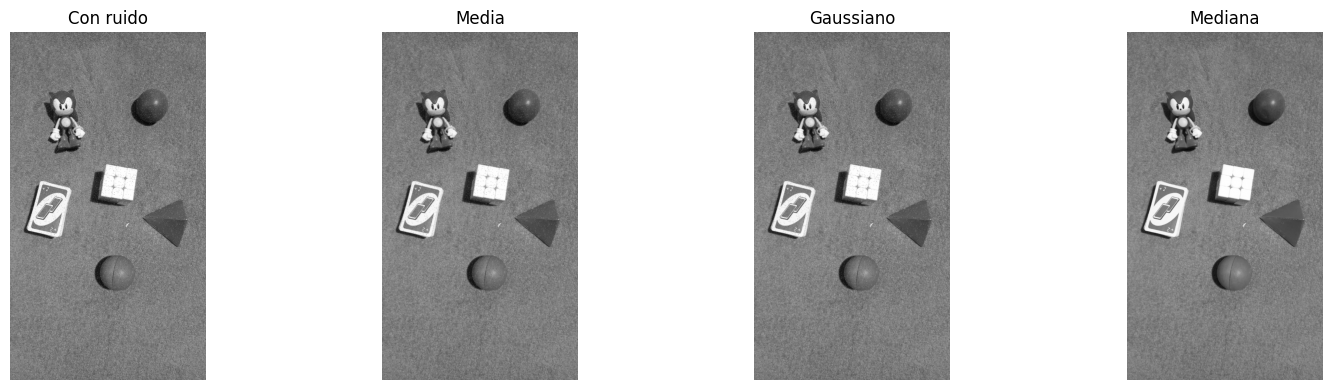

--- Gaussiano (sigma 20) ---
PSNR con ruido: 22.18 dB
PSNR Media     : 25.92 dB
PSNR Gaussiano : 26.93 dB
PSNR Mediana   : 25.30 dB


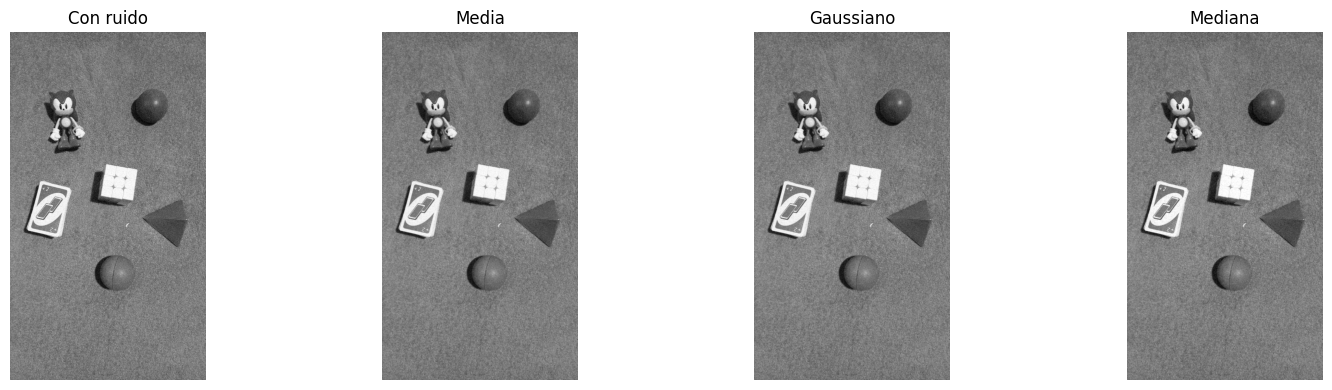

--- Sal y pimienta con ventana 7 ---
PSNR con ruido: 22.74 dB
PSNR Media     : 24.28 dB
PSNR Gaussiano : 25.59 dB
PSNR Mediana   : 24.60 dB


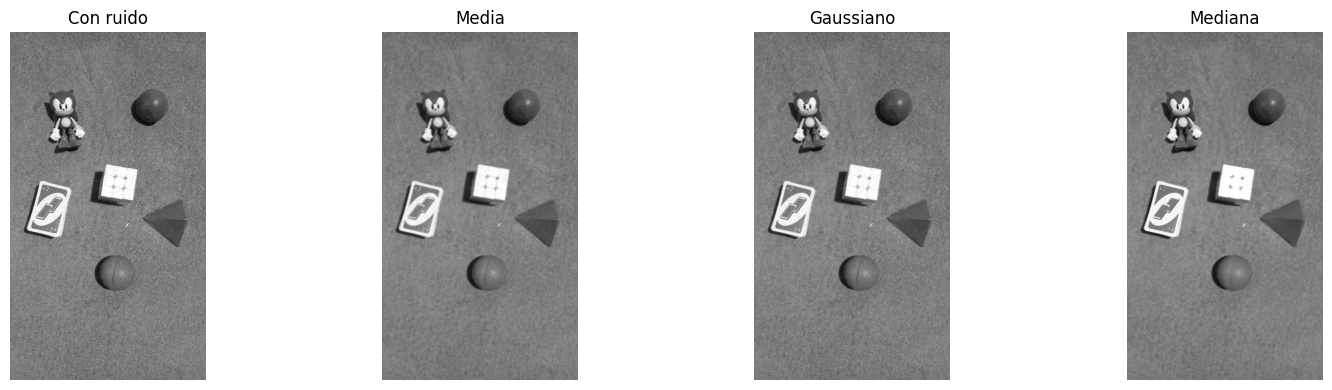

In [25]:
print("--- Sal y pimienta (2 %) ---")
ruidosa = ruido_sal_pimienta(gris, 0.02)
_ = comparar_filtros(ruidosa, gris)

print("--- Gaussiano (sigma 20) ---")
ruidosa_g = ruido_gaussiano(gris, 20)
_ = comparar_filtros(ruidosa_g, gris)

print("--- Sal y pimienta con ventana 7 ---")
_ = comparar_filtros(ruidosa, gris, ventana=7)

Original: media = 66.87
Gamma 0.4: media = 145.32
Gamma 0.5: media = 126.94
Gamma 0.7: media = 97.52
Ecualizada: media = 128.90


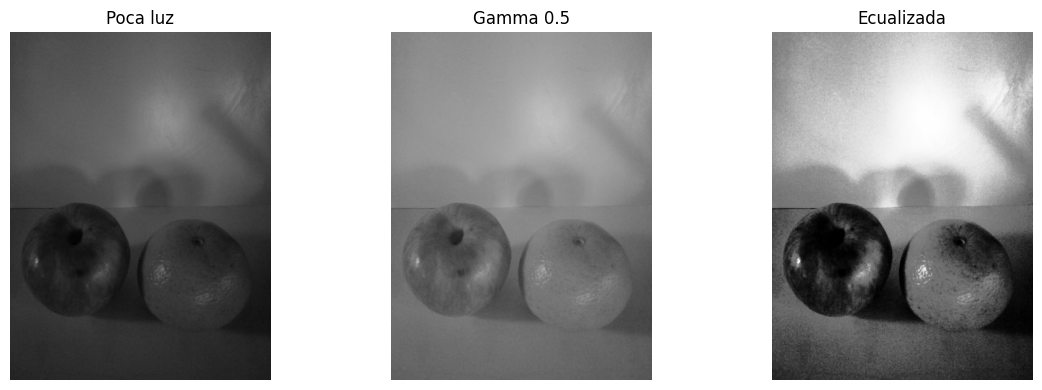

In [26]:
# Pruebas extra para gamma
oscura = cv2.cvtColor(imgs["10_poca_luz.jpg"], cv2.COLOR_BGR2GRAY)
print(f"Original: media = {oscura.mean():.2f}")
for g in (0.4, 0.5, 0.7):
    c = correccion_gamma(oscura, g)
    print(f"Gamma {g}: media = {c.mean():.2f}")
e = ecualizar(oscura)
print(f"Ecualizada: media = {e.mean():.2f}")

mostrar([oscura, correccion_gamma(oscura, 0.5), ecualizar(oscura)],
        ["Poca luz", "Gamma 0.5", "Ecualizada"])

**Decisiones y observaciones:**

**Contraste (imagen `01_cesped_6objetos.jpg`, bien iluminada, media de gris 124,81).** El ajuste lineal (alpha = 1,5; beta = 10) subió la media a 192,92 y saturó las zonas claras. La gamma 0,5 la subió a 176,32 y la gamma 2,0 la bajó a 64,71. La ecualización dejó la media casi igual (129,23) pero usa todo el rango de grises. Como esta foto ya tiene buena luz, ninguna corrección es necesaria.

**Gamma elegida: 0,5.** Se probó sobre la imagen con poca luz (`10_poca_luz.jpg`, media 66,87). Con gamma 0,5 la media pasó a 126,94, es decir, la zona media de la escala, sin saturar píxeles. La gamma 0,4 sobreexpone (media 145,32) y la 0,7 corrige poco (97,52). La ecualización (media 128,90) satura el 2,20 % de los píxeles.

**Cuantización y submuestreo.** Con 4 niveles quedan solo 4 grises (0, 64, 128 y 192) y se pierde el degradé. Con submuestreo 0,25 aparecen escalones (aliasing).

**Filtros de ruido (PSNR en dB, más alto es mejor).**

| Caso | Con ruido | Media | Gaussiano | Mediana |
|---|---|---|---|---|
| Sal y pimienta (2 %), ventana 3 | 22,74 | 26,04 | 27,11 | 27,31 |
| Gaussiano (sigma 20), ventana 3 | 22,18 | 25,92 | 26,93 | 25,30 |
| Sal y pimienta, ventana 7 | 22,74 | 24,28 | 25,59 | 24,60 |

- Para **sal y pimienta** funciona mejor la **mediana** (27,31 dB), porque descarta los valores extremos en vez de promediarlos. La ventaja es chica porque el césped tiene mucha textura fina.
- Para **ruido gaussiano** funciona mejor el filtro **gaussiano** (26,93 dB). La mediana queda última (25,30 dB).
- Con ventana 7 todos los filtros dan peor PSNR que con ventana 3, porque borran más detalle. Se eligió ventana 3.

## 4. Transformaciones geómetricas y morfologia

In [27]:
def rotar(img, angulo, escala=1.0):
    """Rota la imagen. Pista: cv2.getRotationMatrix2D(centro, angulo, escala) + cv2.warpAffine."""
    alto, ancho = img.shape[:2]
    matriz = cv2.getRotationMatrix2D((ancho / 2, alto / 2), angulo, escala)
    return cv2.warpAffine(img, matriz, (ancho, alto))


def escalar(img, fx, fy):
    """Escala la imagen. Pista: cv2.resize(img, None, fx=fx, fy=fy)."""
    interpolacion = cv2.INTER_AREA if (fx < 1 or fy < 1) else cv2.INTER_CUBIC
    return cv2.resize(img, None, fx=fx, fy=fy, interpolation=interpolacion)


def trasladar(img, tx, ty):
    """Traslada la imagen. Pista: M = np.float32([[1,0,tx],[0,1,ty]]) + cv2.warpAffine."""
    alto, ancho = img.shape[:2]
    matriz = np.float32([[1, 0, tx], [0, 1, ty]])
    return cv2.warpAffine(img, matriz, (ancho, alto))


def corregir_perspectiva(img, pts_origen, pts_destino, tam_salida=None):
    """Endereza una figura fotografiada en ángulo.

    Pista: M = cv2.getPerspectiveTransform(pts_origen, pts_destino) + cv2.warpPerspective.
    """
    alto, ancho = img.shape[:2]
    if tam_salida is None:
        tam_salida = (ancho, alto)
    matriz = cv2.getPerspectiveTransform(np.float32(pts_origen), np.float32(pts_destino))
    return cv2.warpPerspective(img, matriz, tam_salida)


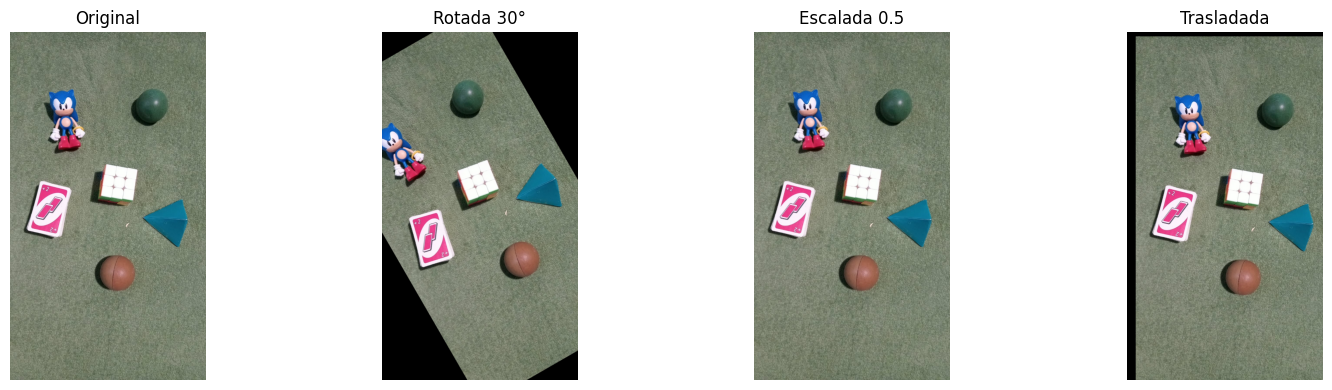

Tamaño original: (1600, 900) | escalada 0.5: (800, 450)


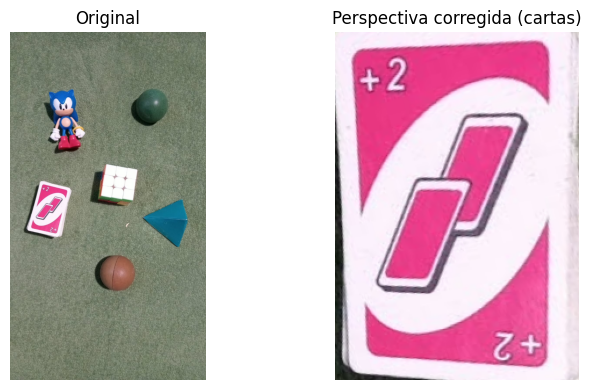

In [28]:
img = imgs["01_cesped_6objetos.jpg"]
mostrar([img, rotar(img, 30), escalar(img, 0.5, 0.5), trasladar(img, 40, 20)],
        ["Original", "Rotada 30°", "Escalada 0.5", "Trasladada"], cols=4)
print("Tamaño original:", img.shape[:2], "| escalada 0.5:", escalar(img, 0.5, 0.5).shape[:2])

# Esquinas del mazo de cartas (orden: sup-izq, sup-der, inf-der, inf-izq)
pts_o = np.float32([[142, 686], [281, 728], [232, 938], [65, 916]])
pts_d = np.float32([[0, 0], [210, 0], [210, 300], [0, 300]])
carta = corregir_perspectiva(img, pts_o, pts_d, tam_salida=(210, 300))
mostrar([img, carta], ["Original", "Perspectiva corregida (cartas)"], cols=2)

In [29]:
def operaciones_morfologicas(img_bin, tam_kernel=5):
    """Erosión, dilatación, apertura y cierre. Devuelve un dict para comparar.

    Pista: kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (tam, tam));
           cv2.erode / cv2.dilate / cv2.morphologyEx(..., MORPH_OPEN / MORPH_CLOSE).
    """
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (tam_kernel, tam_kernel))
    apertura = cv2.morphologyEx(img_bin, cv2.MORPH_OPEN, kernel)
    return {
        "Original": img_bin,
        "Erosion": cv2.erode(img_bin, kernel),
        "Dilatacion": cv2.dilate(img_bin, kernel),
        "Apertura": apertura,
        "Cierre": cv2.morphologyEx(img_bin, cv2.MORPH_CLOSE, kernel),
        "Apertura + Cierre": cv2.morphologyEx(apertura, cv2.MORPH_CLOSE, kernel),
    }

--- Kernel 5x5 ---
Original           blancos =  3.59 %   componentes = 16
Erosion            blancos =  2.83 %   componentes = 31
Dilatacion         blancos =  4.40 %   componentes = 12
Apertura           blancos =  3.52 %   componentes = 12
Cierre             blancos =  3.68 %   componentes = 13
Apertura + Cierre  blancos =  3.56 %   componentes = 9


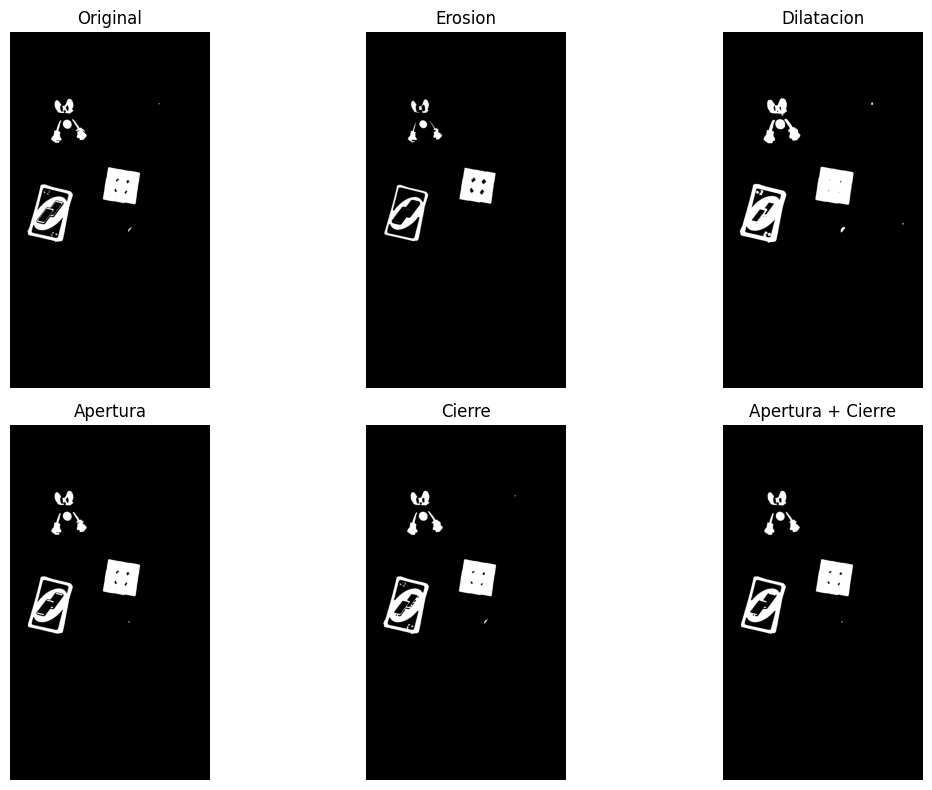

--- Kernel 15x15 ---
Original           blancos =  3.59 %   componentes = 16
Erosion            blancos =  1.41 %   componentes = 15
Dilatacion         blancos =  5.97 %   componentes = 7
Apertura           blancos =  2.95 %   componentes = 10
Cierre             blancos =  4.00 %   componentes = 7
Apertura + Cierre  blancos =  3.01 %   componentes = 9


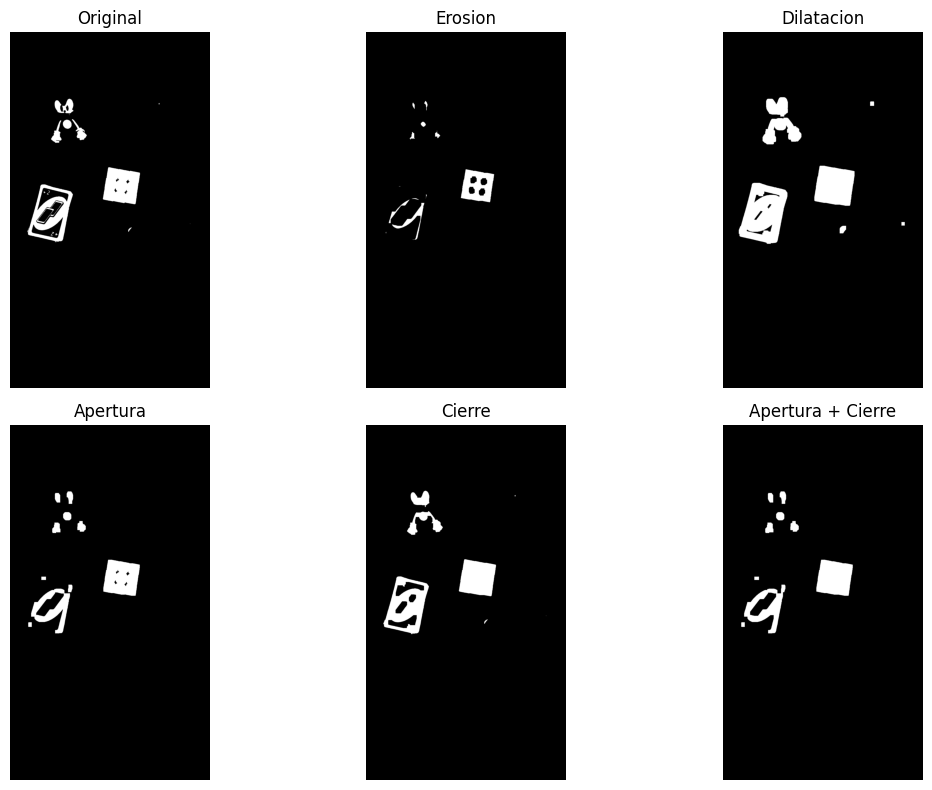

In [30]:
# Máscara binaria con Otsu sobre la imagen en grises
mascara_bin = cv2.threshold(cv2.GaussianBlur(gris, (5, 5), 0), 0, 255,
                            cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]

for tam in (5, 15):
    print(f"--- Kernel {tam}x{tam} ---")
    morf = operaciones_morfologicas(mascara_bin, tam)
    for nombre, m in morf.items():
        blancos = 100 * np.mean(m == 255)
        componentes = cv2.connectedComponents(m)[0] - 1
        print(f"{nombre:<18} blancos = {blancos:5.2f} %   componentes = {componentes}")
    mostrar(list(morf.values()), list(morf.keys()), cols=3, cmap="gray")

**Decisiones y observaciones:**

**Transformaciones geométricas.** Con `cv2.getRotationMatrix2D` y `cv2.warpAffine` se rotó 30° (la imagen conserva el tamaño y se cortan las esquinas). Con `cv2.resize` se escaló a la mitad (de 1600 × 900 a 800 × 450) usando `INTER_AREA` para reducir, que evita el aliasing. La traslación usa una matriz `[[1,0,tx],[0,1,ty]]` con `warpAffine`. Para la perspectiva se marcaron las cuatro esquinas del mazo de cartas y `cv2.getPerspectiveTransform` + `cv2.warpPerspective` lo dejaron de frente en un rectángulo de 210 × 300 px.

**Elemento estructurante.** Se usó un rectángulo (`MORPH_RECT`) de 5 × 5 y otro de 15 × 15, sobre una máscara binaria obtenida con Otsu (umbral 179).

| Operación | Kernel 5: blancos % | Componentes | Kernel 15: blancos % | Componentes |
|---|---|---|---|---|
| Original | 3,59 | 16 | 3,59 | 16 |
| Erosión | 2,83 | 31 | 1,41 | 15 |
| Dilatación | 4,40 | 12 | 5,97 | 7 |
| Apertura | 3,52 | 12 | 2,95 | 10 |
| Cierre | 3,68 | 13 | 4,00 | 7 |
| Apertura + Cierre | 3,56 | 9 | 3,01 | 9 |

- **Apertura:** eliminó manchas blancas chicas (de 16 a 12 componentes con kernel 5) casi sin cambiar el área (3,52 % contra 3,59 %). Sirve para limpiar ruido.
- **Cierre:** rellenó huecos y unió pedazos cercanos (de 16 a 7 componentes con kernel 15), con un poco más de área (4,00 %). Sirve para completar objetos partidos.
- **Apertura + cierre:** dio el menor número de componentes con el kernel chico (9) y mantuvo el área casi igual (3,56 %).
- **Tamaño del elemento:** con 15 × 15 el efecto es mucho más fuerte: la erosión se come más de la mitad del área (1,41 %) y hasta se pierden objetos chicos. Por eso se eligió **5 × 5** para limpiar sin destruir las formas. En el pipeline final se usa un elemento elíptico proporcional al tamaño de la imagen.